In [2]:
import numpy as np
from scipy.constants import h, c, k

import matplotlib.pyplot as plt
from matplotlib.patches import Circle

In [3]:
# found at https://scipython.com/blog/converting-a-spectrum-to-a-colour/

def xyz_from_xy(x, y):
    
    return np.array((x, y, 1-x-y))


class ColourSystem:
    """
    A class representing a colour system.
    
    A colour system defined by the CIE x, y and z(=1-x-y) coordinates of
    its three primary illuminants and its "white point".
    
    TODO: Implement gamma correction
    """
    
    # the CIE colour matching function for 380 - 780 nm in 10 nm intervals
    cmf = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/cie-cmf.txt', usecols=(1,2,3))
        
    def __init__(self, red, green, blue, white):
        """
        Initialise the ColourSystem object.
        
        Pass vectors (i.e. NumPy arrays of shape (3,)) for each of the red, green, blue  
        chromaticities and the white illuminant defining the colour system.
        """
        
        # chromaticities
        self.red, self.green, self.blue = red, green, blue
        self.white = white
        
        # the chromaticity matrix (rgb -> xyz) and its inverse
        self.M = np.vstack((self.red, self.green, self.blue)).T 
        self.MI = np.linalg.inv(self.M)
        
        # white scaling array
        self.wscale = self.MI.dot(self.white)
        
        # xyz -> rgb transformation matrix
        self.T = self.MI / self.wscale[:, np.newaxis]
    
    def xyz_to_rgb(self, xyz, out_fmt=None):
        """
        Transform from xyz to rgb representation of colour.
        
        The output rgb components are normalized on their maximum value.
        If xyz is out the rgb gamut, it is desaturated until it comes into gamut.
        
        By default, fractional rgb components are returned;
        if out_fmt='html', the HTML hex string '#rrggbb' is returned.
        """
        
        rgb = self.T.dot(xyz)
        
        if np.any(rgb < 0):
            # we're not in the RGB gamut: approximate by desaturating
            w = - np.min(rgb)
            rgb += w
            
        if not np.all(rgb == 0):
            # normalize the rgb vector
            rgb /= np.max(rgb)
        
        if out_fmt == 'html':
            return self.rgb_to_hex(rgb)
        
        return rgb
        
    def rgb_to_hex(self, rgb):
        """Convert from fractional rgb values to HTML-style hex string."""
        
        hex_rgb = (255*rgb).astype(int)
        
        return '#{:02x}{:02x}{:02x}'.format(*hex_rgb)

    def spec_to_xyz(self, spec):
        """
        Convert a spectrum to an xyz point.
        
        The spectrum must be on the same grid of points as the colour-matching
        function, self.cmf: 380-780 nm in 5 nm steps.
        """
        
        XYZ = np.sum(spec[:, np.newaxis] * self.cmf, axis=0)
        den = np.sum(XYZ)
        if den == 0.:
            return XYZ
        
        return XYZ / den
    
    def spec_to_rgb(self, spec, out_fmt=None):
        """Convert a spectrum to an rgb value."""
        
        xyz = self.spec_to_xyz(spec)
        
        return self.xyz_to_rgb(xyz, out_fmt)


def planck(lam, T):
    """
    Returns the spectral radiance of a black body at temperature T.
    
    Returns the spectral radiance, B(lam, T), in W.sr-1.m-2 of a black body
    at temperature T (in K) at a wavelength lam (in nm), using Planck's law.
    """

    lam_m = lam / 1.e9
    fac = h*c/lam_m/k/T
    B = 2*h*c**2/lam_m**5 / (np.exp(fac)-1)
    
    return B

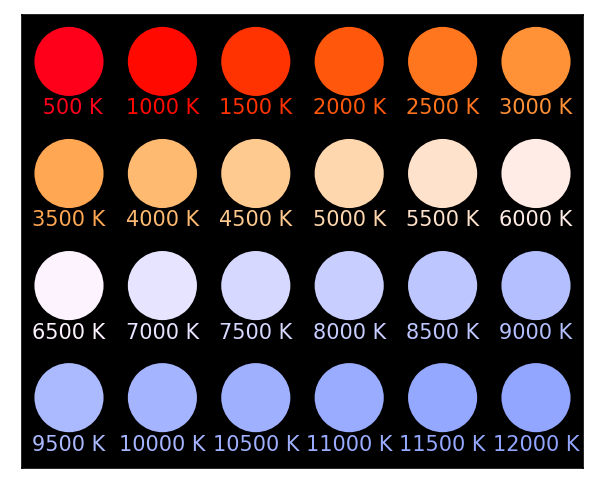

In [4]:
illuminant_D65 = xyz_from_xy(0.3127, 0.3291)

cs_hdtv = ColourSystem(red   = xyz_from_xy(0.67, 0.33),
                       green = xyz_from_xy(0.21, 0.71),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)

cs_smpte = ColourSystem(red   = xyz_from_xy(0.63, 0.34),
                        green = xyz_from_xy(0.31, 0.595),
                        blue  = xyz_from_xy(0.155,0.070),
                        white = illuminant_D65)

cs_srgb = ColourSystem(red   = xyz_from_xy(0.64, 0.33),
                       green = xyz_from_xy(0.30, 0.60),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)
cs = cs_hdtv


# the grid of visible wavelengths corresponding to the grid of
# colour-matching functions used by the ColourSystem instance.

lam = np.arange(380.,781.,5)

fig, ax = plt.subplots(dpi=150)
for i in range(24):
    
    # T = 500 to 12000 K
    T = 500*i + 500

    # calculate the black body spectrum and the HTML hex RGB colour string it looks like
    spec = planck(lam, T)
    html_rgb = cs.spec_to_rgb(spec, out_fmt='html')

    # place and label a circle with the colour of a black body at temperature T
    x, y = i%6, -(i//6)
    circle = Circle(xy=(x,y*1.2), radius=0.37, fc=html_rgb)
    ax.add_patch(circle)
    ax.annotate('{:4d} K'.format(T), xy=(x,y*1.2-0.5), va='center', ha='center', color=html_rgb)

# set the limits and background colour; remove the ticks
ax.set_xlim(-0.5,5.5)
ax.set_ylim(-4.35,0.5)
ax.set_xticks([])
ax.set_yticks([])
ax.set_facecolor('black')

# make sure our circles are circular!
ax.set_aspect('equal')

plt.show()

In [5]:
planck(lam, 500)

array([1.94992043e-17, 4.88354311e-17, 1.19362542e-16, 2.84985347e-16,
       6.65249482e-16, 1.51957110e-15, 3.39923272e-15, 7.45240025e-15,
       1.60244433e-14, 3.38175683e-14, 7.00908776e-14, 1.42762480e-13,
       2.85931094e-13, 5.63446691e-13, 1.09301646e-12, 2.08838579e-12,
       3.93208305e-12, 7.29912665e-12, 1.33645641e-11, 2.41471198e-11,
       4.30710510e-11, 7.58735752e-11, 1.32053137e-10, 2.27154472e-10,
       3.86334120e-10, 6.49864293e-10, 1.08154073e-09, 1.78139757e-09,
       2.90474799e-09, 4.69042819e-09, 7.50230867e-09, 1.18897618e-08,
       1.86749809e-08, 2.90780171e-08, 4.48943670e-08, 6.87452010e-08,
       1.04427234e-07, 1.57398262e-07, 2.35446071e-07, 3.49603470e-07,
       5.15391399e-07, 7.54496464e-07, 1.09701998e-06, 1.58447420e-06,
       2.27374920e-06, 3.24233371e-06, 4.59514569e-06, 6.47341853e-06,
       9.06619713e-06, 1.26251303e-05, 1.74834042e-05, 2.40798518e-05,
       3.29894998e-05, 4.49620828e-05, 6.09703720e-05, 8.22705371e-05,
      

color: #95a8ff


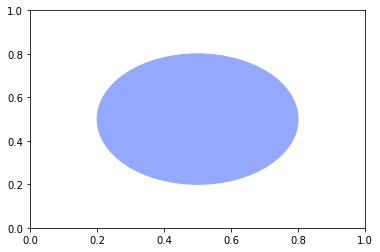

In [7]:
color = cs.spec_to_rgb(planck(lam, 11500), out_fmt='html')
print("color:",color)

fig, ax = plt.subplots()
circle = plt.Circle((0.5, 0.5), .3, color=color)
ax.add_artist(circle);